=== Macroeconomic GDP Growth Summary Metrics ===
Mean:                3.36%
Median:              2.89%
Standard Deviation:  2.48%
IQR (75th - 25th):   1.80%
Skewness:            3.29
Excess Kurtosis:     14.90


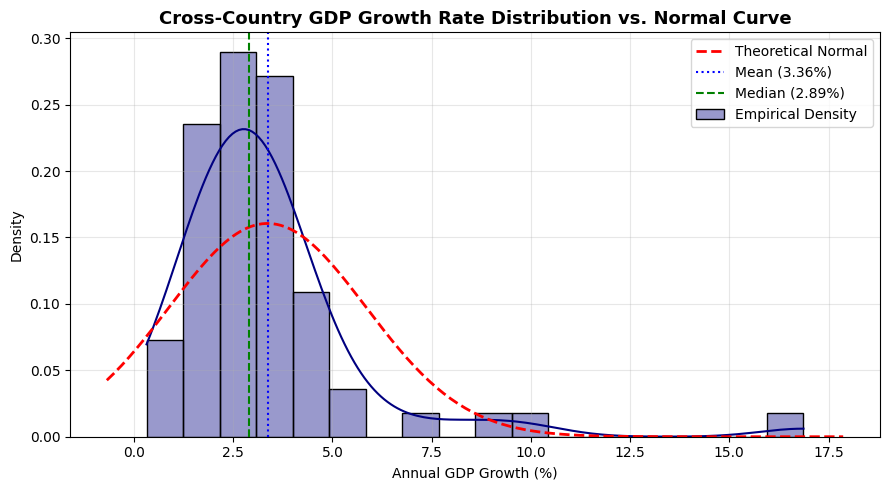

In [ ]:
# Worked Example: Vectorized Macro Summary Statistics & Distribution KDE Fit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Generate synthetic cross-country GDP growth rates (%) for 60 economies
gdp_growth = rng.normal(loc=2.5, scale=1.5, size=60)
# Add some right-skewed emerging market high-growth outliers
gdp_growth[:10] += rng.exponential(scale=3.0, size=10)

df_example = pd.DataFrame({'GDP_Growth': gdp_growth})

# Calculate summary metrics
mean_val = df_example['GDP_Growth'].mean()
median_val = df_example['GDP_Growth'].median()
std_val = df_example['GDP_Growth'].std()
iqr_val = df_example['GDP_Growth'].quantile(0.75) - df_example['GDP_Growth'].quantile(0.25)
skew_val = df_example['GDP_Growth'].skew()
kurt_val = df_example['GDP_Growth'].kurtosis()

print("=== Macroeconomic GDP Growth Summary Metrics ===")
print(f"Mean:                {mean_val:.2f}%")
print(f"Median:              {median_val:.2f}%")
print(f"Standard Deviation:  {std_val:.2f}%")
print(f"IQR (75th - 25th):   {iqr_val:.2f}%")
print(f"Skewness:            {skew_val:.2f}")
print(f"Excess Kurtosis:     {kurt_val:.2f}")

# Plot KDE distribution with normal curve overlay
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df_example['GDP_Growth'], kde=True, stat="density", color="navy", alpha=0.4, label="Empirical Density", ax=ax)

# Overlay theoretical normal distribution
x_axis = np.linspace(df_example['GDP_Growth'].min() - 1, df_example['GDP_Growth'].max() + 1, 200)
normal_pdf = stats.norm.pdf(x_axis, mean_val, std_val)
ax.plot(x_axis, normal_pdf, 'r--', linewidth=2, label="Theoretical Normal")

ax.axvline(mean_val, color='blue', linestyle=':', label=f'Mean ({mean_val:.2f}%)')
ax.axvline(median_val, color='green', linestyle='--', label=f'Median ({median_val:.2f}%)')

ax.set_title("Cross-Country GDP Growth Rate Distribution vs. Normal Curve", fontsize=13, fontweight='bold')
ax.set_xlabel("Annual GDP Growth (%)")
ax.set_ylabel("Density")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def audit_macro_indicators(seed: int = 42) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Generate macroeconomic panel data, calculate comprehensive parametric
    and non-parametric summary statistics, and construct diagnostic distribution plots.

    Parameters:
    -----------
    seed : int, default=42
        Random seed for reproducibility.

    Returns:
    --------
    tuple[pd.DataFrame, pd.DataFrame]
        - summary_df: DataFrame of summary statistics
        - df_macro: DataFrame of the 50 national economies
    """

    rng = np.random.default_rng(seed)

    # Group definitions
    n_g7 = 7
    n_non_g7 = 43

    groups = ["G7"] * n_g7 + ["Non-G7"] * n_non_g7

    # Simulate macro indicators
    gdp_growth = np.concatenate([
        rng.normal(1.8, 0.8, n_g7),
        rng.normal(3.5, 2.2, n_non_g7)
    ])

    inflation = np.concatenate([
        rng.normal(2.1, 0.5, n_g7),
        rng.normal(5.8, 3.1, n_non_g7)
    ])

    unemployment = np.concatenate([
        rng.normal(4.8, 1.1, n_g7),
        rng.normal(7.2, 2.5, n_non_g7)
    ])

    public_debt = np.concatenate([
        rng.normal(110.0, 25.0, n_g7),
        rng.normal(62.0, 20.0, n_non_g7)
    ])

    # Create dataframe
    df_macro = pd.DataFrame({
        "Group": groups,
        "GDP_Growth": gdp_growth,
        "Inflation": inflation,
        "Unemployment": unemployment,
        "Public_Debt": public_debt
    })

    # Summary statistics
    indicators = [
        "GDP_Growth",
        "Inflation",
        "Unemployment",
        "Public_Debt"
    ]

    summary = []

    for col in indicators:
        s = df_macro[col]

        q25 = s.quantile(0.25)
        q75 = s.quantile(0.75)

        summary.append({
            "Mean": s.mean(),
            "Median": s.median(),
            "Std Dev": s.std(),
            "Q25": q25,
            "Q75": q75,
            "IQR": q75 - q25,
            "Skewness": s.skew(),
            "Kurtosis": s.kurtosis()
        })

    summary_df = pd.DataFrame(
        summary,
        index=indicators
    ).round(3)

    # Publication-grade figure
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Panel A: KDE plot
    sns.kdeplot(
        data=df_macro,
        x="GDP_Growth",
        hue="Group",
        fill=True,
        ax=axes[0]
    )

    axes[0].set_title(
        "Panel A: GDP Growth KDE Distribution"
    )
    axes[0].set_xlabel("GDP Growth (%)")
    axes[0].grid(alpha=0.3)

    # Panel B: Public Debt Boxplot
    sns.boxplot(
        data=df_macro,
        x="Group",
        y="Public_Debt",
        ax=axes[1]
    )

    axes[1].set_title(
        "Panel B: Public Debt Comparison"
    )
    axes[1].set_ylabel("Public Debt (% GDP)")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return summary_df, df_macro

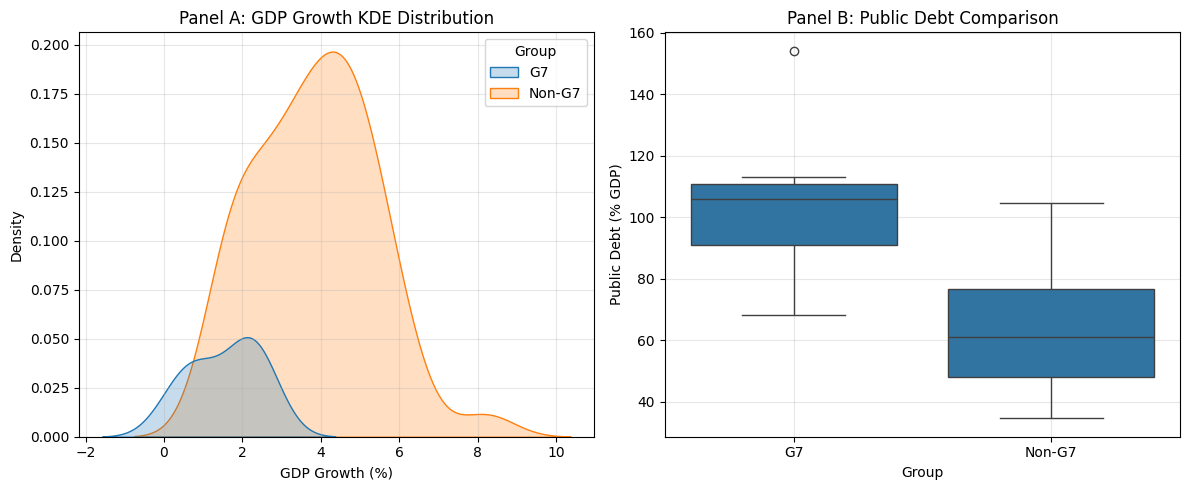

=== Global Macroeconomic Indicator Audit Summary Table ===


,Mean,Median,Std Dev,Q25,Q75,IQR,Skewness,Kurtosis
GDP_Growth,3.523,3.554,1.653,2.126,4.689,2.563,0.284,-0.082
Inflation,4.804,4.697,2.543,2.319,7.208,4.889,0.112,-1.076
Unemployment,6.758,6.477,2.565,4.677,8.065,3.388,0.656,0.557
Public_Debt,69.168,65.558,24.644,52.236,84.121,31.886,0.955,1.394



=== Sample of First 5 Economies ===


,Group,GDP_Growth,Inflation,Unemployment,Public_Debt
0,G7,2.043774,2.244560,4.384021,106.034129
1,G7,0.968013,2.415644,6.229151,84.108656
2,G7,2.400361,1.371422,4.408110,68.132926
3,G7,2.552452,1.940164,5.611267,97.842302
4,G7,0.239172,1.864814,3.773021,108.655436


In [ ]:
# Output Inspection: Exercise 1
# Run your function and inspect summary statistics table and distribution plots

summary_df, df_macro = audit_macro_indicators(seed=42)

if summary_df is not None:
    print("=== Global Macroeconomic Indicator Audit Summary Table ===")
    display(summary_df.round(3))

    print("\n=== Sample of First 5 Economies ===")
    display(df_macro.head())


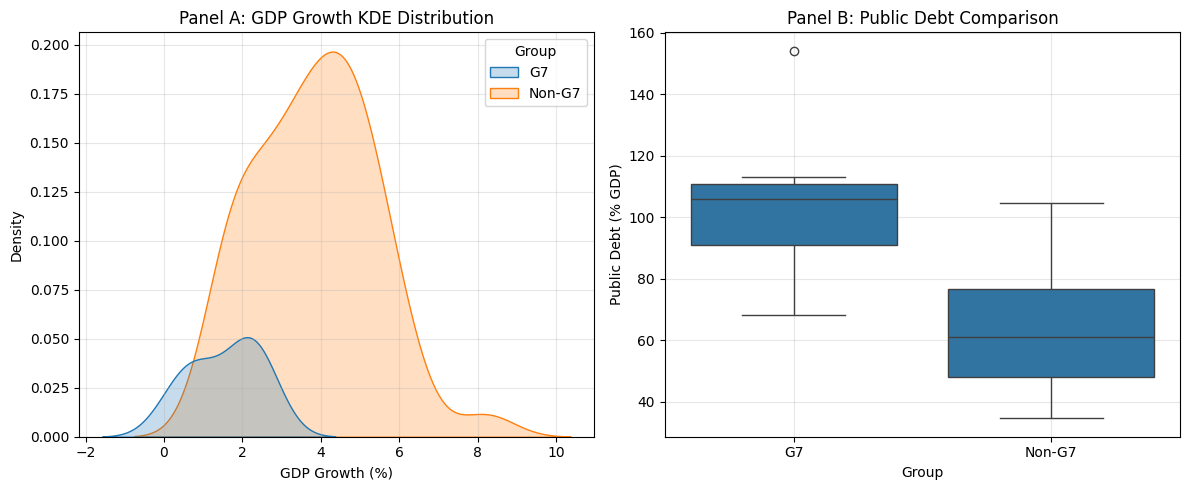

Exercise 1 validation passed successfully! All statistical and structure assertions confirmed.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def audit_macro_indicators(seed: int = 42) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Generate macroeconomic panel data, calculate comprehensive parametric
    and non-parametric summary statistics, and construct diagnostic distribution plots.

    Parameters:
    -----------
    seed : int, default=42
        Random seed for reproducibility.

    Returns:
    --------
    tuple[pd.DataFrame, pd.DataFrame]
        - summary_df: DataFrame of summary statistics
        - df_macro: DataFrame of the 50 national economies
    """

    rng = np.random.default_rng(seed)

    # Group definitions
    n_g7 = 7
    n_non_g7 = 43

    groups = ["G7"] * n_g7 + ["Non-G7"] * n_non_g7

    # Simulate macro indicators
    gdp_growth = np.concatenate([
        rng.normal(1.8, 0.8, n_g7),
        rng.normal(3.5, 2.2, n_non_g7)
    ])

    inflation = np.concatenate([
        rng.normal(2.1, 0.5, n_g7),
        rng.normal(5.8, 3.1, n_non_g7)
    ])

    unemployment = np.concatenate([
        rng.normal(4.8, 1.1, n_g7),
        rng.normal(7.2, 2.5, n_non_g7)
    ])

    public_debt = np.concatenate([
        rng.normal(110.0, 25.0, n_g7),
        rng.normal(62.0, 20.0, n_non_g7)
    ])

    # Create dataframe
    df_macro = pd.DataFrame({
        "Group": groups,
        "GDP_Growth": gdp_growth,
        "Inflation": inflation,
        "Unemployment": unemployment,
        "Public_Debt": public_debt
    })

    # Summary statistics
    indicators = [
        "GDP_Growth",
        "Inflation",
        "Unemployment",
        "Public_Debt"
    ]

    summary = []

    for col in indicators:
        s = df_macro[col]

        q25 = s.quantile(0.25)
        q75 = s.quantile(0.75)

        summary.append({
            "Mean": s.mean(),
            "Median": s.median(),
            "Std Dev": s.std(),
            "Q25": q25,
            "Q75": q75,
            "IQR": q75 - q25,
            "Skewness": s.skew(),
            "Kurtosis": s.kurtosis()
        })

    summary_df = pd.DataFrame(
        summary,
        index=indicators
    ).round(3)

    # Publication-grade figure
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Panel A: KDE plot
    sns.kdeplot(
        data=df_macro,
        x="GDP_Growth",
        hue="Group",
        fill=True,
        ax=axes[0]
    )

    axes[0].set_title(
        "Panel A: GDP Growth KDE Distribution"
    )
    axes[0].set_xlabel("GDP Growth (%)")
    axes[0].grid(alpha=0.3)

    # Panel B: Public Debt Boxplot
    sns.boxplot(
        data=df_macro,
        x="Group",
        y="Public_Debt",
        ax=axes[1]
    )

    axes[1].set_title(
        "Panel B: Public Debt Comparison"
    )
    axes[1].set_ylabel("Public Debt (% GDP)")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return summary_df, df_macro


# Automated Validation Test: Exercise 1
# Do not modify this cell. Run it to verify your implementation.

test_summary, test_macro = audit_macro_indicators(seed=42)

# 1. Type assertions
assert isinstance(test_summary, pd.DataFrame), "summary_df must be a pd.DataFrame."
assert isinstance(test_macro, pd.DataFrame), "df_macro must be a pd.DataFrame."

# 2. DataFrame dimensions and indices
assert len(test_macro) == 50, f"Expected 50 countries, got {len(test_macro)}"
expected_indicators = {'GDP_Growth', 'Inflation', 'Unemployment', 'Public_Debt'}
assert set(test_summary.index) == expected_indicators, f"Summary index must contain {expected_indicators}"

# 3. Required metric columns
expected_metrics = {'Mean', 'Median', 'Std Dev', 'Q25', 'Q75', 'IQR', 'Skewness', 'Kurtosis'}
assert expected_metrics.issubset(test_summary.columns), f"Summary columns must include {expected_metrics}"

# 4. Mathematical consistency checks
for ind in expected_indicators:
    row = test_summary.loc[ind]
    assert np.isclose(row['IQR'], row['Q75'] - row['Q25'], atol=1e-3), f"IQR must equal Q75 - Q25 for {ind}"
    assert row['Std Dev'] > 0, f"Standard deviation must be strictly positive for {ind}"

print("Exercise 1 validation passed successfully! All statistical and structure assertions confirmed.")


1. Code Logic & Statistical Mechanics
The median is less affected by extreme values, so it better represents the typical economy. Standard deviation is sensitive to outliers, while IQR focuses on the middle 50% of observations and is more robust.
2. Empirical Econometrics & Economic Interpretation
Non-G7 economies generally have higher but more volatile GDP growth. G7 economies tend to have higher public debt. Advanced economies can sustain more debt because of strong institutions, credible policies, and well-developed financial markets.
3. AI Collaboration & Econometric Audit
Skewness shows whether data are asymmetric, while kurtosis measures the presence of extreme values (fat tails). These metrics help identify economic and financial risks that mean and standard deviation alone may miss.

In [ ]:
# Worked Example: Two-Sample T-Test & Mann-Whitney U Test on Policy Reforms
import numpy as np
import pandas as pd
from scipy import stats

rng = np.random.default_rng(123)

# Regional retail sales growth post-tax reform (% change)
treatment_regions = rng.normal(loc=4.2, scale=1.4, size=30)  # Regions receiving reform
control_regions = rng.normal(loc=2.8, scale=1.2, size=30)    # Control regions

# Parametric Independent Two-Sample T-Test
t_stat, p_val_t = stats.ttest_ind(treatment_regions, control_regions)

# Non-Parametric Mann-Whitney U Test
u_stat, p_val_u = stats.mannwhitneyu(treatment_regions, control_regions)

print("=== Tax Reform Impact Assessment ===")
print(f"Treatment Mean Growth: {treatment_regions.mean():.2f}% | Control Mean Growth: {control_regions.mean():.2f}%")
print(f"Mean Difference:       {treatment_regions.mean() - control_regions.mean():.2f}%")
print(f"Two-Sample T-Test:     t-statistic = {t_stat:.3f}, p-value = {p_val_t:.4f}")
print(f"Mann-Whitney U Test:   U-statistic = {u_stat:.1f}, p-value = {p_val_u:.4f}")
if p_val_t < 0.05:
    print("Result: Statistically significant policy impact at 5% significance level (Reject H0).")
else:
    print("Result: Fail to reject H0 (No significant policy effect).")

=== Tax Reform Impact Assessment ===
Treatment Mean Growth: 4.51% | Control Mean Growth: 2.76%
Mean Difference:       1.75%
Two-Sample T-Test:     t-statistic = 5.476, p-value = 0.0000
Mann-Whitney U Test:   U-statistic = 758.0, p-value = 0.0000
Result: Statistically significant policy impact at 5% significance level (Reject H0).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def evaluate_fiscal_stimulus(seed: int = 101) -> dict:

    rng = np.random.default_rng(seed)

    # Simulate spending growth
    high_stimulus = rng.normal(loc=3.8, scale=1.5, size=30)
    low_stimulus = rng.normal(loc=2.2, scale=1.3, size=30)

    # One-sample t-test
    t_one, p_one = stats.ttest_1samp(high_stimulus, popmean=2.5)

    # Two-sample t-test
    t_two, p_two = stats.ttest_ind(high_stimulus, low_stimulus)

    # Means
    high_mean = high_stimulus.mean()
    low_mean = low_stimulus.mean()
    diff_mean = high_mean - low_mean

    # 95% Confidence Interval
    se = np.sqrt(
        high_stimulus.var(ddof=1) / len(high_stimulus) +
        low_stimulus.var(ddof=1) / len(low_stimulus)
    )

    ci_lower = diff_mean - 1.96 * se
    ci_upper = diff_mean + 1.96 * se

    # Mann-Whitney U test
    u_stat, p_u = stats.mannwhitneyu(
        high_stimulus,
        low_stimulus,
        alternative="two-sided"
    )

    # Plot
    means = [high_mean, low_mean]
    errors = [
        1.96 * high_stimulus.std(ddof=1) / np.sqrt(len(high_stimulus)),
        1.96 * low_stimulus.std(ddof=1) / np.sqrt(len(low_stimulus))
    ]

    plt.figure(figsize=(6,4))
    plt.bar(
        ["High Stimulus", "Low Stimulus"],
        means,
        yerr=errors,
        capsize=5,
        color=["steelblue", "orange"]
    )

    plt.ylabel("Consumer Spending Growth (%)")
    plt.title("Fiscal Stimulus and Consumer Spending")
    plt.grid(alpha=0.3)
    plt.show()

    return {
        "high_mean": high_mean,
        "low_mean": low_mean,
        "diff_mean": diff_mean,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "t_one": t_one,
        "p_one": p_one,
        "t_two": t_two,
        "p_two": p_two,
        "u_stat": u_stat,
        "p_u": p_u
    }

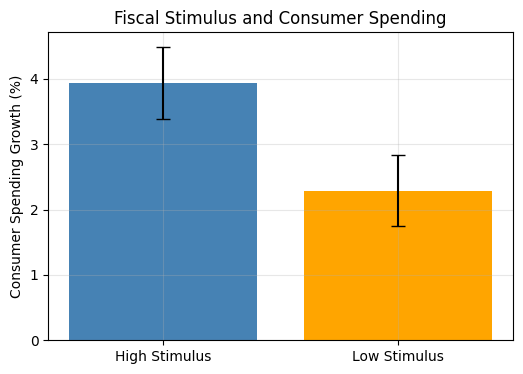

=== Regional Fiscal Stimulus Hypothesis Testing Audit ===
High Stimulus Group Mean: 3.937%
Low Stimulus Group Mean:  2.288%
Difference in Means:      1.648% (95% CI: [0.875%, 2.422%])
-------------------------------------------------------
1-Sample t-test vs 2.5%:   t = 5.125, p-value = 0.00002
2-Sample t-test (A vs B):  t = 4.176, p-value = 0.00010
Mann-Whitney U Test:       U = 694.0, p-value = 0.00032

Policy Conclusion: The fiscal stimulus generated a statistically significant increase in retail spending.


In [ ]:
stim_results = evaluate_fiscal_stimulus(seed=101)

if stim_results is not None:
    print("=== Regional Fiscal Stimulus Hypothesis Testing Audit ===")
    print(f"High Stimulus Group Mean: {stim_results['high_mean']:.3f}%")
    print(f"Low Stimulus Group Mean:  {stim_results['low_mean']:.3f}%")
    print(f"Difference in Means:      {stim_results['diff_mean']:.3f}% (95% CI: [{stim_results['ci_lower']:.3f}%, {stim_results['ci_upper']:.3f}%])")
    print("-" * 55)
    print(f"1-Sample t-test vs 2.5%:   t = {stim_results['t_one']:.3f}, p-value = {stim_results['p_one']:.5f}")
    print(f"2-Sample t-test (A vs B):  t = {stim_results['t_two']:.3f}, p-value = {stim_results['p_two']:.5f}")
    print(f"Mann-Whitney U Test:       U = {stim_results['u_stat']:.1f}, p-value = {stim_results['p_u']:.5f}")

    if stim_results['p_two'] < 0.05 and stim_results['p_u'] < 0.05:
        print("\nPolicy Conclusion: The fiscal stimulus generated a statistically significant increase in retail spending.")

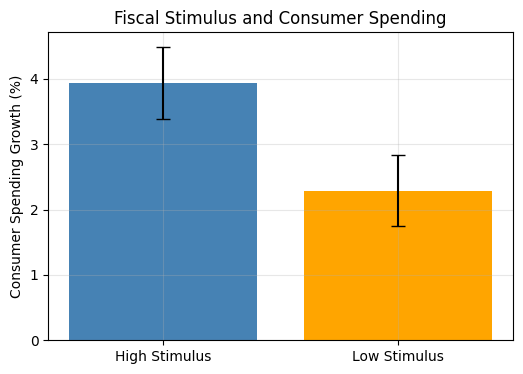

Exercise 2 validation passed successfully! All hypothesis testing and confidence interval assertions confirmed.


In [ ]:
# Automated Validation Test: Exercise 2
# Do not modify this cell. Run it to verify your implementation.

test_stim = evaluate_fiscal_stimulus(seed=101)

assert isinstance(test_stim, dict), "evaluate_fiscal_stimulus must return a dictionary."
required_keys = {'high_mean', 'low_mean', 'diff_mean', 'ci_lower', 'ci_upper', 't_one', 'p_one', 't_two', 'p_two', 'u_stat', 'p_u'}
assert required_keys.issubset(test_stim.keys()), f"Result dict must contain keys: {required_keys}"

# 1. Verify policy impact direction: high stimulus > low stimulus
assert test_stim['high_mean'] > test_stim['low_mean'], "High stimulus mean should exceed low stimulus mean."
assert test_stim['diff_mean'] > 0, "Difference in means must be positive."

# 2. Verify confidence interval bounds
assert test_stim['ci_lower'] < test_stim['diff_mean'] < test_stim['ci_upper'], "Confidence interval must bracket the difference in means."
assert (test_stim['ci_upper'] - test_stim['ci_lower']) > 0, "CI width must be strictly positive."

# 3. Verify statistical significance at alpha = 0.05
assert test_stim['p_one'] < 0.05, f"1-sample test p-value should be < 0.05, got {test_stim['p_one']:.4f}"
assert test_stim['p_two'] < 0.05, f"2-sample test p-value should be < 0.05, got {test_stim['p_two']:.4f}"
assert test_stim['p_u'] < 0.05, f"Mann-Whitney U p-value should be < 0.05, got {test_stim['p_u']:.4f}"

print("Exercise 2 validation passed successfully! All hypothesis testing and confidence interval assertions confirmed.")


1. Code Logic & Statistical Mechanics
Student Response Area:
The two-sample t-test compares whether the means of two groups are equal. The Mann-Whitney U test compares the ranks of observations without assuming normality. The Mann-Whitney U test is preferred when data are skewed, contain outliers, or do not follow a normal distribution.
2. Empirical Econometrics & Economic Interpretation
Student Response Area:
If the 95% confidence interval does not include zero, it suggests that the stimulus had a statistically significant positive effect on consumer spending. This means the likelihood of the true effect being zero or negative is low, giving policymakers more confidence in the policy.
3. AI Collaboration & Econometric Audit
Student Response Area:
This practice is called p-hacking. It is problematic because repeatedly testing different groups increases the chance of finding misleading significant results. Economists should report all results transparently, mention p-values honestly, and use methods such as multiple-testing corrections when necessary.

In [ ]:
# Worked Example: Multiple OLS Regression for Inflation Determinants
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

rng = np.random.default_rng(42)
n_obs = 100

# Synthetic Macro Variables
money_growth = rng.normal(5.0, 1.5, n_obs)       # Money Supply M2 Growth (%)
unemployment = rng.normal(6.0, 1.2, n_obs)         # Unemployment Rate (%)
oil_price_change = rng.normal(2.0, 4.0, n_obs)     # Energy Import Price Change (%)

# Inflation data generation process: pi = 0.5 + 0.6*M - 0.4*U + 0.15*Oil + e
error = rng.normal(0, 0.8, n_obs)
inflation = 0.5 + 0.6 * money_growth - 0.4 * unemployment + 0.15 * oil_price_change + error

df_ols = pd.DataFrame({
    'inflation': inflation,
    'money_growth': money_growth,
    'unemployment': unemployment,
    'oil_price_change': oil_price_change
})

# Fit OLS Regression Model
model_example = smf.ols(formula='inflation ~ money_growth + unemployment + oil_price_change', data=df_ols).fit()

print("=== Macroeconomic Inflation OLS Model Summary ===")
print(model_example.summary().tables[1])
print(f"\nR-Squared:          {model_example.rsquared:.4f}")
print(f"Adjusted R-Squared: {model_example.rsquared_adj:.4f}")
print(f"F-Statistic:        {model_example.fvalue:.2f} (p-value: {model_example.f_pvalue:.4e})")

=== Macroeconomic Inflation OLS Model Summary ===
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.8406      0.524      1.603      0.112      -0.201       1.882
money_growth         0.6620      0.070      9.401      0.000       0.522       0.802
unemployment        -0.4922      0.070     -7.052      0.000      -0.631      -0.354
oil_price_change     0.1432      0.020      7.184      0.000       0.104       0.183

R-Squared:          0.6472
Adjusted R-Squared: 0.6362
F-Statistic:        58.70 (p-value: 1.2187e-21)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

def estimate_phillips_curve(seed: int = 2024):
    """
    Estimate an augmented Empirical Phillips Curve multiple OLS regression
    and construct publication-grade regression diagnostic plots.

    Parameters:
    -----------
    seed : int, default=2024
        Random seed for reproducibility.

    Returns:
    --------
    statsmodels.regression.linear_model.RegressionResultsWrapper
        Fitted OLS regression model object.
    """

    rng = np.random.default_rng(seed)

    n_obs = 80

    unemployment = rng.normal(5.5, 1.0, n_obs)
    money_growth = rng.normal(4.0, 1.2, n_obs)
    energy_index = rng.normal(100.0, 10.0, n_obs)

    error = rng.normal(0, 0.6, n_obs)

    inflation = (
        2.0
        - 0.55 * unemployment
        + 0.45 * money_growth
        + 0.05 * (energy_index - 100)
        + error
    )

    df_pc = pd.DataFrame({
        "inflation": inflation,
        "unemployment": unemployment,
        "money_growth": money_growth,
        "energy_index": energy_index
    })

    model = smf.ols(
        formula="inflation ~ unemployment + money_growth + energy_index",
        data=df_pc
    ).fit()

    # Two-panel figure
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Panel A
    sns.regplot(
        data=df_pc,
        x="unemployment",
        y="inflation",
        ax=axes[0],
        line_kws={"color": "red"}
    )

    axes[0].set_title("Panel A: Phillips Curve")
    axes[0].set_xlabel("Unemployment (%)")
    axes[0].set_ylabel("Inflation (%)")
    axes[0].grid(alpha=0.3)

    # Panel B
    axes[1].plot(
        df_pc.index,
        df_pc["inflation"],
        label="Actual Inflation"
    )

    axes[1].plot(
        df_pc.index,
        model.fittedvalues,
        label="Fitted Inflation",
        linestyle="--"
    )

    axes[1].set_title("Panel B: Actual vs Fitted Inflation")
    axes[1].set_xlabel("Quarter")
    axes[1].set_ylabel("Inflation (%)")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return model

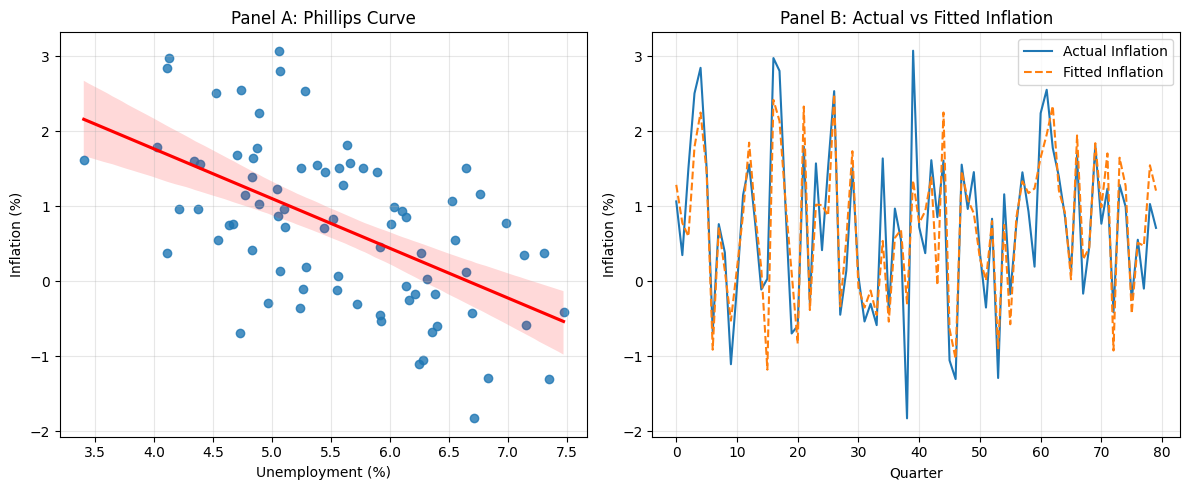

=== Augmented Phillips Curve OLS Regression Summary ===
                            OLS Regression Results                            
Dep. Variable:              inflation   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.759
Method:                 Least Squares   F-statistic:                     83.76
Date:                Wed, 30 Sep 2026   Prob (F-statistic):           4.95e-24
Time:                        08:36:10   Log-Likelihood:                -60.072
No. Observations:                  80   AIC:                             128.1
Df Residuals:                      76   BIC:                             137.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------

,Coefficient (Beta),Std Error,t-statistic,p-value,95% CI Lower,95% CI Upper
Intercept,-2.2246,0.6744,-3.2984,0.0015,-3.5679,-0.8813
unemployment,-0.7433,0.0664,-11.2026,0.0000,-0.8755,-0.6112
money_growth,0.3977,0.0495,8.0276,0.0000,0.2990,0.4964
energy_index,0.0556,0.0058,9.5753,0.0000,0.0440,0.0671


In [ ]:
# Output Inspection: Exercise 3
# Run your function and inspect OLS regression results and Phillips curve trade-off

pc_model = estimate_phillips_curve(seed=2024)

if pc_model is not None:
    print("=== Augmented Phillips Curve OLS Regression Summary ===")
    print(pc_model.summary())

    print("\n=== Key Econometric Coefficients & Elasticities ===")
    coeff_summary = pd.DataFrame({
        'Coefficient (Beta)': pc_model.params,
        'Std Error': pc_model.bse,
        't-statistic': pc_model.tvalues,
        'p-value': pc_model.pvalues,
        '95% CI Lower': pc_model.conf_int()[0],
        '95% CI Upper': pc_model.conf_int()[1]
    })
    display(coeff_summary.round(4))


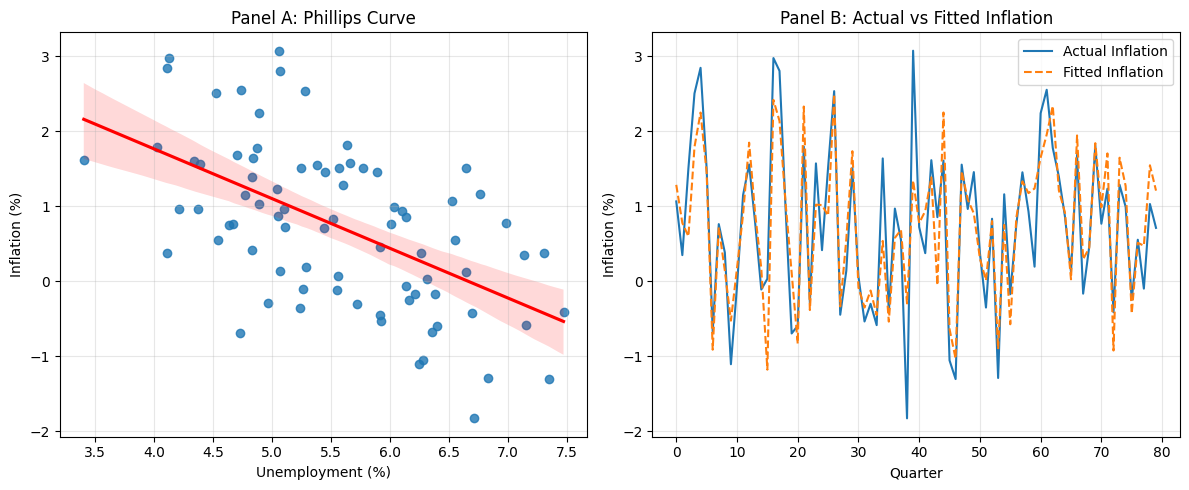

Exercise 3 validation passed successfully! All Phillips Curve econometric assertions confirmed.


In [ ]:
# Automated Validation Test: Exercise 3
# Do not modify this cell. Run it to verify your implementation.

test_pc = estimate_phillips_curve(seed=2024)

assert test_pc is not None, "estimate_phillips_curve must return a fitted model object."
assert hasattr(test_pc, 'params'), "Returned object must be a statsmodels regression results object."

# 1. Check regressor presence in model
required_vars = {'Intercept', 'unemployment', 'money_growth', 'energy_index'}
assert set(test_pc.params.index) == required_vars, f"Expected variables {required_vars}, got {set(test_pc.params.index)}"

# 2. Check Phillips Curve slope (negative and statistically significant)
unemp_beta = test_pc.params['unemployment']
unemp_pval = test_pc.pvalues['unemployment']
assert unemp_beta < -0.3, f"Expected negative Phillips Curve slope (< -0.3), got {unemp_beta:.4f}"
assert unemp_pval < 0.05, f"Expected statistically significant unemployment coefficient (p < 0.05), got p={unemp_pval:.4e}"

# 3. Check money growth and energy index signs
assert test_pc.params['money_growth'] > 0, "Money growth coefficient should be positive."
assert test_pc.params['energy_index'] > 0, "Energy index coefficient should be positive."

# 4. Check goodness-of-fit R^2
assert test_pc.rsquared > 0.50, f"Expected R^2 > 0.50, got {test_pc.rsquared:.3f}"

print("Exercise 3 validation passed successfully! All Phillips Curve econometric assertions confirmed.")


1. Code Logic & Statistical Mechanics
In multiple regression, the effect of unemployment is estimated while controlling for money growth and energy index. This allows the model to isolate the partial effect of unemployment on inflation and reduce the influence of other variables.
2. Empirical Econometrics & Economic Interpretation
If the energy index increases sharply, inflation can rise because production and transportation costs become higher. This may lead to stagflation, where inflation and unemployment are both high at the same time. In this model, this is reflected by the positive energy index coefficient, which pushes inflation upward even when unemployment remains high.
3. AI Collaboration & Econometric Audit
To avoid overly complex models, AI should be instructed to include only variables supported by economic theory and research. It is important to limit unnecessary variables, check for multicollinearity, and prefer a simple, interpretable model instead of a “kitchen sink” regression with too many predictors.

In [ ]:
# Worked Example: Breusch-Pagan Test, Robust HC3 SEs & VIF Diagnostics
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

rng = np.random.default_rng(42)
n_obs = 100

# Predictors
x1 = rng.normal(10, 2, n_obs)
x2 = x1 * 0.8 + rng.normal(0, 1, n_obs)  # Highly correlated with x1 (Multicollinearity)

# Heteroskedastic error: variance increases with x1
het_error = rng.normal(0, 0.5 * x1, n_obs)
y = 2.0 + 1.5 * x1 - 0.4 * x2 + het_error

df_diag = pd.DataFrame({'y': y, 'x1': x1, 'x2': x2})

# 1. Standard OLS Fit
model_std = smf.ols('y ~ x1 + x2', data=df_diag).fit()

# 2. Breusch-Pagan Test for Heteroskedasticity
bp_test = het_breuschpagan(model_std.resid, model_std.model.exog)
print(f"Breusch-Pagan Test LM Statistic: {bp_test[0]:.3f}, p-value: {bp_test[1]:.4f}")

# 3. Robust HC3 SE Estimation
model_hc3 = smf.ols('y ~ x1 + x2', data=df_diag).fit(cov_type='HC3')
print("\n=== Standard Errors Comparison (Standard vs Robust HC3) ===")
comparison_df = pd.DataFrame({
    'Standard SE': model_std.bse,
    'Robust HC3 SE': model_hc3.bse,
    'Standard p-val': model_std.pvalues,
    'HC3 p-val': model_hc3.pvalues
})
print(comparison_df.round(4))

# 4. Variance Inflation Factor (VIF)
X_matrix = model_std.model.exog
vif_data = pd.DataFrame({
    'Variable': model_std.model.exog_names,
    'VIF': [variance_inflation_factor(X_matrix, i) for i in range(X_matrix.shape[1])]
})
print("\n=== Variance Inflation Factor (VIF) ===")
print(vif_data.round(2))

Breusch-Pagan Test LM Statistic: 4.305, p-value: 0.1162

=== Standard Errors Comparison (Standard vs Robust HC3) ===
           Standard SE  Robust HC3 SE  Standard p-val  HC3 p-val
Intercept       3.4137         3.2632          0.3746     0.3507
x1              0.5751         0.6038          0.0287     0.0344
x2              0.5403         0.5801          0.5892     0.6139

=== Variance Inflation Factor (VIF) ===
    Variable   VIF
0  Intercept  1.00
1         x1  2.87
2         x2  2.87


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.graphics.gofplots import qqplot


def diagnose_regional_development(seed: int = 888) -> dict:

    rng = np.random.default_rng(seed)

    n = 80

    # Generate variables
    infrastructure = rng.normal(50.0, 15.0, n)

    literacy = rng.normal(85.0, 8.0, n)

    industrial_output = (
        0.7 * infrastructure
        + rng.normal(0, 5.0, n)
    )

    # Heteroskedastic errors
    error = rng.normal(
        0,
        0.15 * infrastructure,
        n
    )

    gdp_per_capita = (
        5.0
        + 0.4 * infrastructure
        + 0.3 * literacy
        + 0.2 * industrial_output
        + error
    )

    # DataFrame
    df = pd.DataFrame({
        "gdp_per_capita": gdp_per_capita,
        "infrastructure": infrastructure,
        "literacy": literacy,
        "industrial_output": industrial_output
    })

    # Standard OLS
    model_std = smf.ols(
        "gdp_per_capita ~ infrastructure + literacy + industrial_output",
        data=df
    ).fit()

    # Breusch-Pagan Test
    bp_test = het_breuschpagan(
        model_std.resid,
        model_std.model.exog
    )

    bp_pvalue = bp_test[1]

    # HC3 Robust OLS
    model_hc3 = smf.ols(
        "gdp_per_capita ~ infrastructure + literacy + industrial_output",
        data=df
    ).fit(cov_type="HC3")

    # VIF
    X = model_std.model.exog

    vif_df = pd.DataFrame({
        "Variable": model_std.model.exog_names,
        "VIF": [
            variance_inflation_factor(X, i)
            for i in range(X.shape[1])
        ]
    })

    # Diagnostic Plots
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Panel A: Residuals vs Fitted
    axes[0].scatter(
        model_std.fittedvalues,
        model_std.resid,
        alpha=0.7
    )

    axes[0].axhline(
        0,
        color="red",
        linestyle="--"
    )

    axes[0].set_title(
        "Residuals vs Fitted"
    )

    axes[0].set_xlabel(
        "Fitted Values"
    )

    axes[0].set_ylabel(
        "Residuals"
    )

    # Panel B: QQ Plot
    qqplot(
        model_std.resid,
        line="45",
        ax=axes[1]
    )

    axes[1].set_title(
        "Normal Q-Q Plot"
    )

    plt.tight_layout()
    plt.show()

    return {
        "model_std": model_std,
        "model_hc3": model_hc3,
        "bp_pvalue": bp_pvalue,
        "vif_df": vif_df
    }

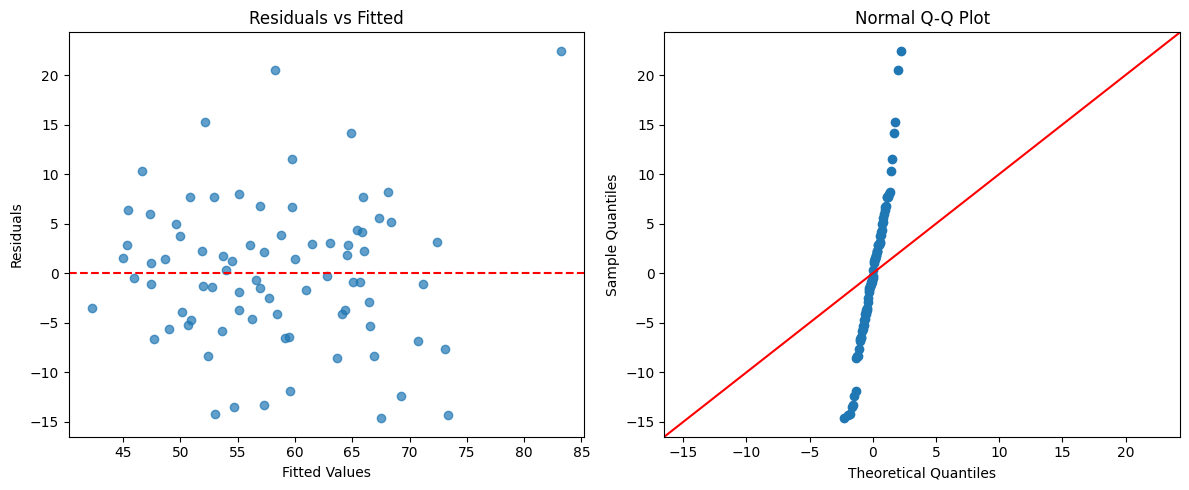

=== Breusch-Pagan Heteroskedasticity Diagnostic Test ===
Breusch-Pagan Test p-value: 0.03686
-> Heteroskedasticity DETECTED (p < 0.05). OLS standard errors are biased; HC3 standard errors required.

=== Multicollinearity Diagnostics (Variance Inflation Factor) ===


,Variable,VIF
0,Intercept,1.0
1,infrastructure,5.4
2,literacy,1.0
3,industrial_output,5.4



=== Comparison: Standard vs. HC3 Robust Standard Errors ===


,Coefficient,Standard SE,HC3 Robust SE,Std t-stat,HC3 t-stat,HC3 p-value
Intercept,11.4808,9.8323,11.6754,1.1677,0.9833,0.3254
infrastructure,0.4150,0.1267,0.1177,3.2748,3.5245,0.0004
literacy,0.2207,0.1056,0.1102,2.0888,2.0017,0.0453
industrial_output,0.1634,0.1741,0.1333,0.9385,1.2257,0.2203


In [ ]:
# Output Inspection: Exercise 4
# Run your function and inspect diagnostic test results and standard error adjustments

diag_results = diagnose_regional_development(seed=888)

if diag_results is not None:
    print("=== Breusch-Pagan Heteroskedasticity Diagnostic Test ===")
    print(f"Breusch-Pagan Test p-value: {diag_results['bp_pvalue']:.5f}")
    if diag_results['bp_pvalue'] < 0.05:
        print("-> Heteroskedasticity DETECTED (p < 0.05). OLS standard errors are biased; HC3 standard errors required.")

    print("\n=== Multicollinearity Diagnostics (Variance Inflation Factor) ===")
    display(diag_results['vif_df'].round(2))

    print("\n=== Comparison: Standard vs. HC3 Robust Standard Errors ===")
    se_comp = pd.DataFrame({
        'Coefficient': diag_results['model_std'].params,
        'Standard SE': diag_results['model_std'].bse,
        'HC3 Robust SE': diag_results['model_hc3'].bse,
        'Std t-stat': diag_results['model_std'].tvalues,
        'HC3 t-stat': diag_results['model_hc3'].tvalues,
        'HC3 p-value': diag_results['model_hc3'].pvalues
    })
    display(se_comp.round(4))


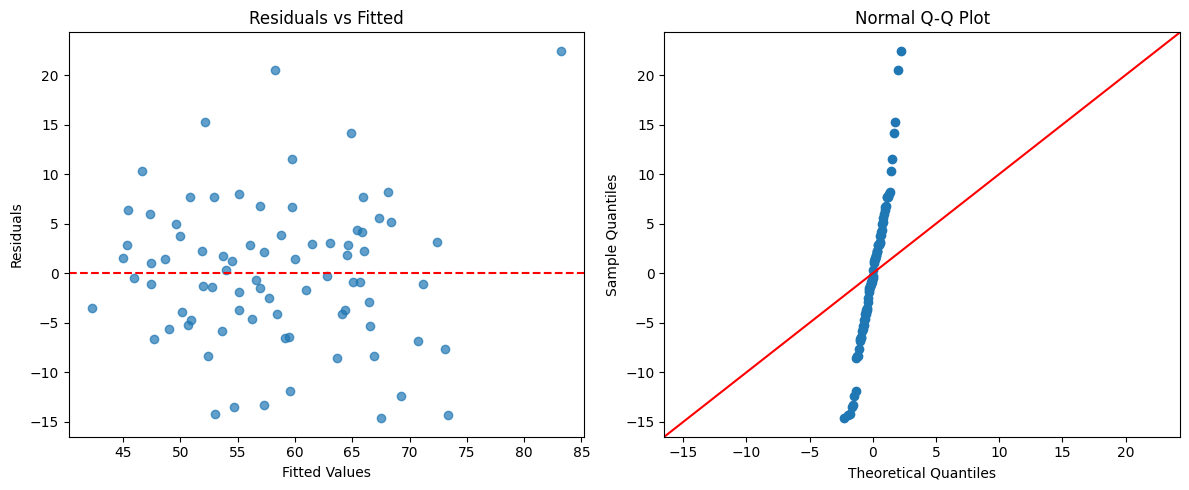

Exercise 4 validation passed successfully! All heteroskedasticity, HC3 SE, and VIF assertions confirmed.


In [ ]:
# Automated Validation Test: Exercise 4
# Do not modify this cell. Run it to verify your implementation.

test_diag = diagnose_regional_development(seed=888)

assert isinstance(test_diag, dict), "diagnose_regional_development must return a dict."
required_keys = {'model_std', 'model_hc3', 'bp_pvalue', 'vif_df'}
assert required_keys.issubset(test_diag.keys()), f"Result dict must contain keys: {required_keys}"

# 1. Breusch-Pagan detects heteroskedasticity (p < 0.05)
assert test_diag['bp_pvalue'] < 0.05, f"Expected BP p-value < 0.05, got {test_diag['bp_pvalue']:.4f}"

# 2. VIF DataFrame structure and high VIF for infrastructure/industrial_output
vif = test_diag['vif_df']
assert isinstance(vif, pd.DataFrame), "vif_df must be a pd.DataFrame."
assert 'Variable' in vif.columns and 'VIF' in vif.columns, "vif_df must contain 'Variable' and 'VIF' columns."
infra_vif = vif.loc[vif['Variable'] == 'infrastructure', 'VIF'].values[0]
assert infra_vif > 2.0, f"Expected infrastructure VIF > 2.0 due to collinearity, got {infra_vif:.2f}"

# 3. HC3 robust standard errors should differ from standard OLS standard errors
std_se = test_diag['model_std'].bse['infrastructure']
hc3_se = test_diag['model_hc3'].bse['infrastructure']
assert not np.isclose(std_se, hc3_se, rtol=1e-3), "HC3 standard error should differ from unadjusted OLS standard error."

print("Exercise 4 validation passed successfully! All heteroskedasticity, HC3 SE, and VIF assertions confirmed.")


1. Code Logic & Statistical Mechanics:
When heteroskedasticity is present, OLS coefficient estimates remain unbiased and consistent. However, the standard errors become unreliable. As a result, t-statistics, p-values, and confidence intervals may be incorrect, leading to wrong conclusions about statistical significance.
2. Empirical Econometrics & Economic Interpretation:
Infrastructure, industrial investment, and capital stock are often closely related because regions with strong infrastructure usually attract more investment and economic activity. High VIF values indicate multicollinearity, which increases standard errors and makes it difficult to separate the individual effects of each variable.
3. AI Collaboration & Econometric Audit:
Removing a highly correlated variable may reduce multicollinearity, but it can also create omitted variable bias if the variable is economically important. Before dropping a variable, economists should consider economic theory, check model performance, and compare results from different model specifications to ensure the decision is justified.

In [ ]:
# Worked Example: ADF Test, Differencing & ARIMA(1,1,1) Forecasting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

rng = np.random.default_rng(42)

# Generate non-stationary random walk interest rate series
steps = 120
rate_changes = rng.normal(loc=0.02, scale=0.25, size=steps)
policy_rate = np.cumsum(rate_changes) + 3.0

df_ts = pd.DataFrame({'Policy_Rate': policy_rate})

# 1. ADF Test on Levels
adf_level = adfuller(df_ts['Policy_Rate'])
print(f"ADF Statistic (Level): {adf_level[0]:.3f}, p-value: {adf_level[1]:.4f}")

# 2. First Difference & ADF Test
df_ts['Rate_Diff'] = df_ts['Policy_Rate'].diff()
adf_diff = adfuller(df_ts['Rate_Diff'].dropna())
print(f"ADF Statistic (1st Diff): {adf_diff[0]:.3f}, p-value: {adf_diff[1]:.4f}")

# 3. Fit ARIMA(1,1,1)
arima_model = ARIMA(df_ts['Policy_Rate'], order=(1,1,1)).fit()
print("\n=== ARIMA(1,1,1) Model Summary ===")
print(arima_model.summary().tables[1])

# 4. Out-of-sample Forecast
forecast_res = arima_model.get_forecast(steps=12)
fc_mean = forecast_res.predicted_mean
fc_ci = forecast_res.conf_int()

print("\n12-Month Ahead Policy Rate Forecast:")
print(fc_mean.round(2))

/tmp/ipykernel_1498/4084844089.py:19: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_level = adfuller(df_ts['Policy_Rate'])
/tmp/ipykernel_1498/4084844089.py:24: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(df_ts['Rate_Diff'].dropna())


ADF Statistic (Level): -1.482, p-value: 0.5423
ADF Statistic (1st Diff): -10.626, p-value: 0.0000

=== ARIMA(1,1,1) Model Summary ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2246      4.171      0.054      0.957      -7.950       8.399
ma.L1         -0.2015      4.193     -0.048      0.962      -8.419       8.016
sigma2         0.0384      0.005      7.090      0.000       0.028       0.049

12-Month Ahead Policy Rate Forecast:
120    3.59
121    3.59
122    3.59
123    3.59
124    3.59
125    3.59
126    3.59
127    3.59
128    3.59
129    3.59
130    3.59
131    3.59
Name: predicted_mean, dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

def forecast_policy_rate(seed: int = 555) -> dict:

    rng = np.random.default_rng(seed)

    n = 120

    # AR(1) shock process
    shocks = np.zeros(n)

    for t in range(1, n):
        shocks[t] = (
            0.80 * shocks[t - 1]
            + rng.normal(0, 0.2)
        )

    # Policy rate level
    policy_rate = 2.5 + np.cumsum(0.1 * shocks)

    df = pd.DataFrame({
        "Policy_Rate": policy_rate
    })

    # ADF tests
    adf_level = adfuller(df["Policy_Rate"])
    adf_level_pval = adf_level[1]

    df["Rate_Diff"] = df["Policy_Rate"].diff()

    adf_diff = adfuller(
        df["Rate_Diff"].dropna()
    )
    adf_diff_pval = adf_diff[1]

    # ARIMA(1,1,1)
    arima_model = ARIMA(
        df["Policy_Rate"],
        order=(1, 1, 1)
    ).fit()

    # Ljung-Box test
    lb_test = acorr_ljungbox(
        arima_model.resid,
        lags=[10],
        return_df=True
    )

    # Forecast
    forecast_res = arima_model.get_forecast(
        steps=12
    )

    forecast_mean = forecast_res.predicted_mean
    forecast_ci = forecast_res.conf_int()

    # Figure
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(13, 5)
    )

    # Panel A: Forecast Fan Chart
    axes[0].plot(
        df.index,
        df["Policy_Rate"],
        label="Historical Rate"
    )

    future_idx = np.arange(
        len(df),
        len(df) + 12
    )

    axes[0].plot(
        future_idx,
        forecast_mean,
        color="red",
        label="Forecast"
    )

    axes[0].fill_between(
        future_idx,
        forecast_ci.iloc[:, 0],
        forecast_ci.iloc[:, 1],
        color="red",
        alpha=0.2,
        label="95% CI"
    )

    axes[0].set_title(
        "Panel A: Policy Rate Forecast"
    )

    axes[0].set_ylabel(
        "Policy Rate (%)"
    )

    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Panel B: Residual Distribution
    sns.histplot(
        arima_model.resid,
        kde=True,
        color="steelblue",
        ax=axes[1]
    )

    axes[1].axvline(
        0,
        color="red",
        linestyle="--"
    )

    axes[1].set_title(
        "Panel B: ARIMA Residuals"
    )

    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return {
        "adf_level_pval": adf_level_pval,
        "adf_diff_pval": adf_diff_pval,
        "arima_model": arima_model,
        "forecast_mean": forecast_mean,
        "forecast_ci": forecast_ci
    }

/tmp/ipykernel_1498/3180013362.py:33: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_level = adfuller(df["Policy_Rate"])
/tmp/ipykernel_1498/3180013362.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(


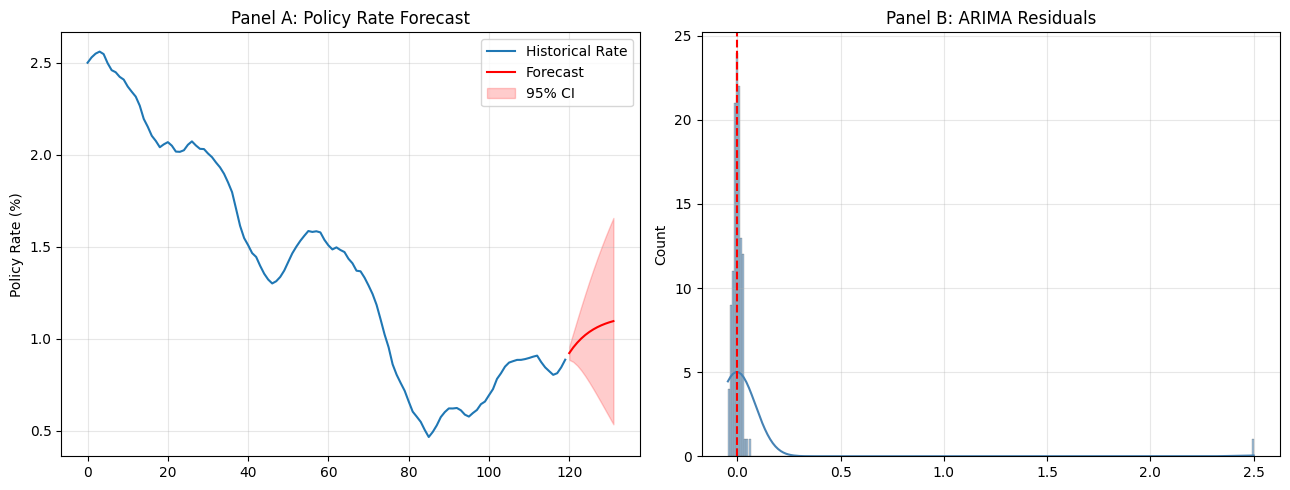

=== Central Bank Policy Rate Time-Series Diagnostics ===
ADF Level p-value:             0.1914 -> Non-Stationary I(1)
ADF First-Difference p-value:  0.0232 -> Stationary I(0)

=== ARIMA(1,1,1) Parameter Estimates ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8552      0.057     15.114      0.000       0.744       0.966
ma.L1          0.0286      0.130      0.220      0.826      -0.227       0.284
sigma2         0.0004    4.4e-05      7.947      0.000       0.000       0.000

=== 12-Month Ahead Policy Rate Forecast Fan Projections ===


,Forecast Rate (%),95% Lower Bound,95% Upper Bound
120,0.922,0.886,0.959
121,0.953,0.875,1.031
122,0.979,0.855,1.104
123,1.002,0.829,1.175
124,1.021,0.798,1.244
125,1.037,0.764,1.311
126,1.051,0.728,1.375
127,1.063,0.690,1.436
128,1.074,0.652,1.495
129,1.082,0.613,1.552


In [ ]:
# Output Inspection: Exercise 5
# Run your function and inspect time-series stationarity and ARIMA forecast metrics

fc_results = forecast_policy_rate(seed=555)

if fc_results is not None:
    print("=== Central Bank Policy Rate Time-Series Diagnostics ===")
    print(f"ADF Level p-value:             {fc_results['adf_level_pval']:.4f} " +
          ("-> Non-Stationary I(1)" if fc_results['adf_level_pval'] > 0.05 else "-> Stationary I(0)"))
    print(f"ADF First-Difference p-value:  {fc_results['adf_diff_pval']:.4f} " +
          ("-> Stationary I(0)" if fc_results['adf_diff_pval'] < 0.05 else "-> Non-Stationary"))

    print("\n=== ARIMA(1,1,1) Parameter Estimates ===")
    print(fc_results['arima_model'].summary().tables[1])

    print("\n=== 12-Month Ahead Policy Rate Forecast Fan Projections ===")
    fc_table = pd.DataFrame({
        'Forecast Rate (%)': fc_results['forecast_mean'],
        '95% Lower Bound': fc_results['forecast_ci'].iloc[:, 0],
        '95% Upper Bound': fc_results['forecast_ci'].iloc[:, 1]
    })
    display(fc_table.round(3))


/tmp/ipykernel_1498/3180013362.py:33: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_level = adfuller(df["Policy_Rate"])
/tmp/ipykernel_1498/3180013362.py:38: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(


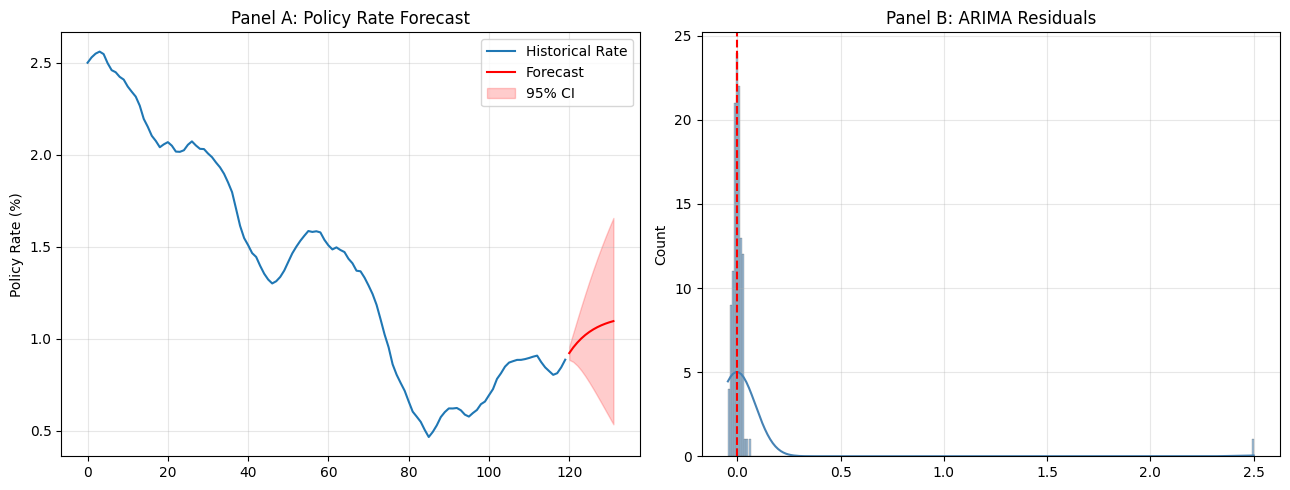

Exercise 5 validation passed successfully! All stationarity and ARIMA forecast assertions confirmed.


In [ ]:
# Automated Validation Test: Exercise 5
# Do not modify this cell. Run it to verify your implementation.

test_fc = forecast_policy_rate(seed=555)

assert isinstance(test_fc, dict), "forecast_policy_rate must return a dict."
required_keys = {'adf_level_pval', 'adf_diff_pval', 'arima_model', 'forecast_mean', 'forecast_ci'}
assert required_keys.issubset(test_fc.keys()), f"Result dict must contain keys: {required_keys}"

# 1. Stationarity verification: level series is I(1), differenced is I(0)
assert test_fc['adf_level_pval'] > 0.05, f"Expected non-stationary level (p > 0.05), got p={test_fc['adf_level_pval']:.4f}"
assert test_fc['adf_diff_pval'] < 0.05, f"Expected stationary 1st diff (p < 0.05), got p={test_fc['adf_diff_pval']:.4f}"

# 2. Forecast dimensions
assert len(test_fc['forecast_mean']) == 12, f"Expected 12 forecast periods, got {len(test_fc['forecast_mean'])}"
assert len(test_fc['forecast_ci']) == 12, f"Expected 12 confidence interval rows, got {len(test_fc['forecast_ci'])}"

# 3. Confidence interval consistency (lower < mean < upper)
ci_lower = test_fc['forecast_ci'].iloc[:, 0].values
ci_upper = test_fc['forecast_ci'].iloc[:, 1].values
means = test_fc['forecast_mean'].values
assert np.all(ci_lower < means), "Forecast lower CI bounds must be strictly less than forecast means."
assert np.all(means < ci_upper), "Forecast upper CI bounds must be strictly greater than forecast means."

print("Exercise 5 validation passed successfully! All stationarity and ARIMA forecast assertions confirmed.")


1. Code Logic & Statistical Mechanics
Non-stationary time series often follow similar trends over time, which can create misleading correlations. This may produce high R² values and significant t-statistics even when there is no real relationship. First-differencing or using ARIMA with d=1 removes the trend component and helps make the series stationary, reducing the risk of spurious regression.
2. Empirical Econometrics & Economic Interpretation
The confidence intervals become wider because forecast uncertainty increases over time. Small prediction errors accumulate at longer horizons. For central banks, short-term forecasts are usually more reliable, while long-term forecasts are more uncertain and should be interpreted with caution when guiding inflation expectations.
3. AI Collaboration & Econometric Audit
To avoid overfitting, the proposed model should be simple and supported by theory. Economists should compare in-sample and out-of-sample performance, use backtesting, and check residual diagnostics. A more complex model is not always better, especially when the dataset is small.